<a href="https://colab.research.google.com/github/2405112/ML_Tugas2/blob/main/Kelompok_5_ML_TI24D_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

RANDOM_STATE = 42

In [3]:
df = pd.read_csv("heart.csv")
print("Jumlah baris, kolom:", df.shape)
df.head()

Jumlah baris, kolom: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.info()
print()
print("Missing value per kolom:")
print(df.isnull().sum())
print()
print("Jumlah data duplikat:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Missing value per kolom:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina  

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


HeartDisease
1    508
0    410
Name: count, dtype: int64


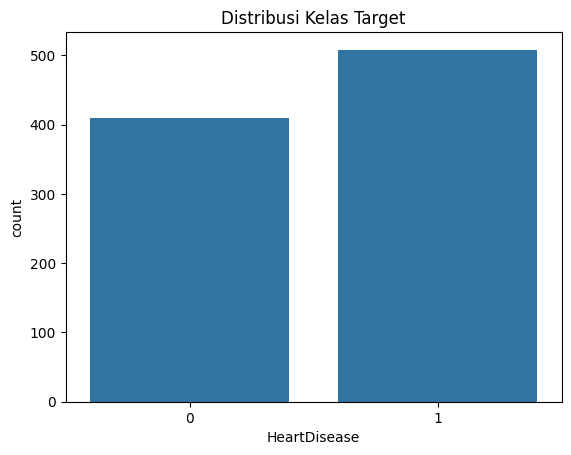

Cholesterol = 0: 172
RestingBP   = 0: 1


In [5]:
# Distribusi kelas target
print(df["HeartDisease"].value_counts())
sns.countplot(x="HeartDisease", data=df)
plt.title("Distribusi Kelas Target")
plt.show()

# Nilai 0 yang janggal (kemungkinan data hilang)
print("Cholesterol = 0:", (df["Cholesterol"] == 0).sum())
print("RestingBP   = 0:", (df["RestingBP"] == 0).sum())

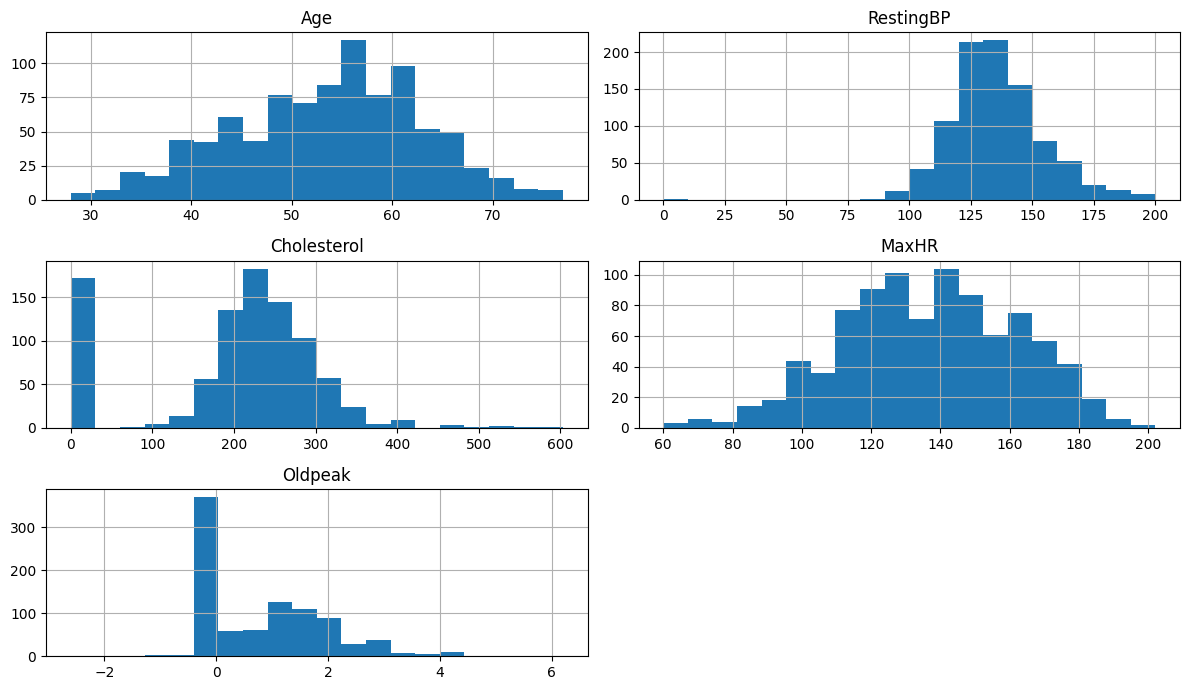

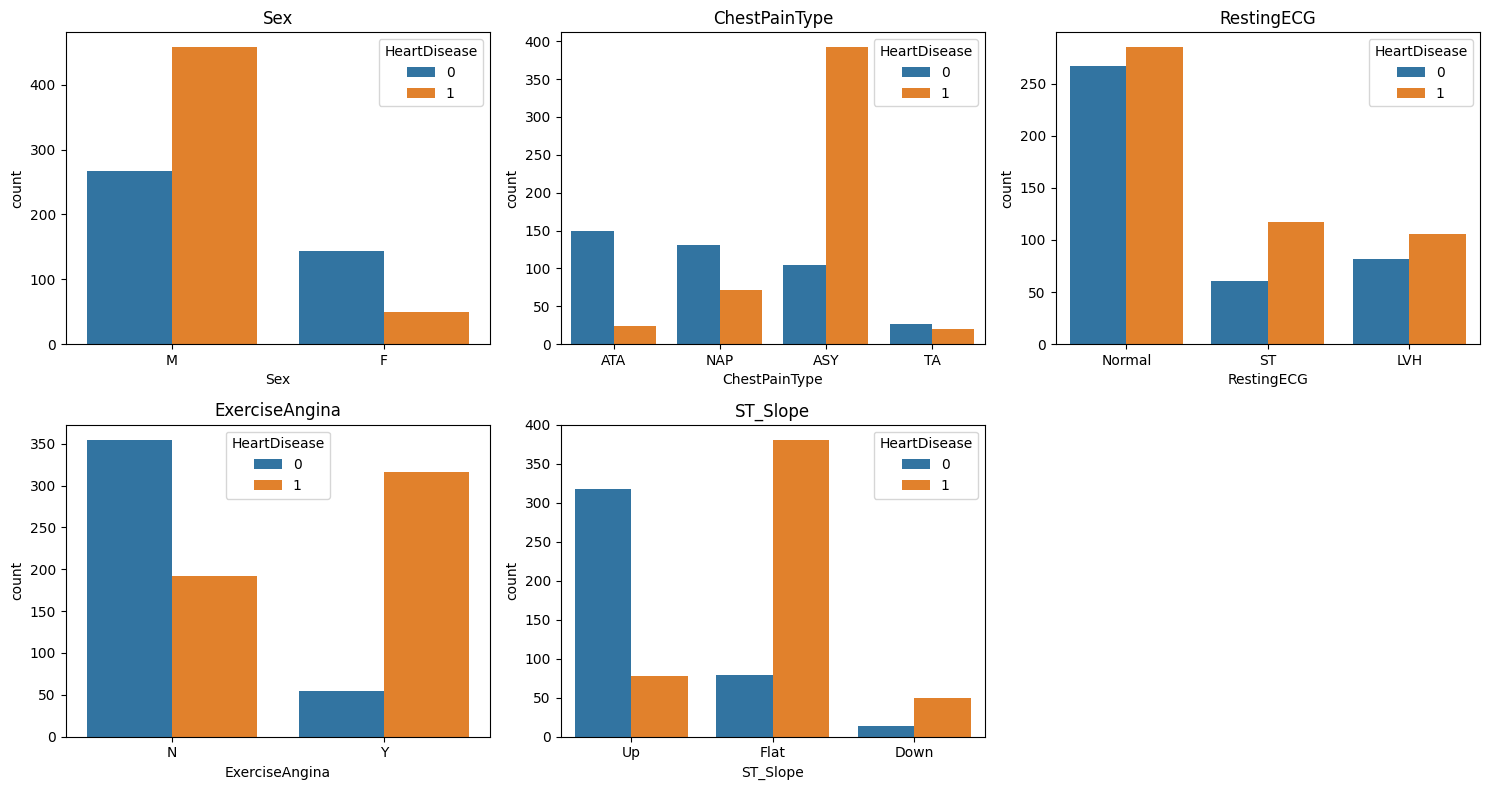

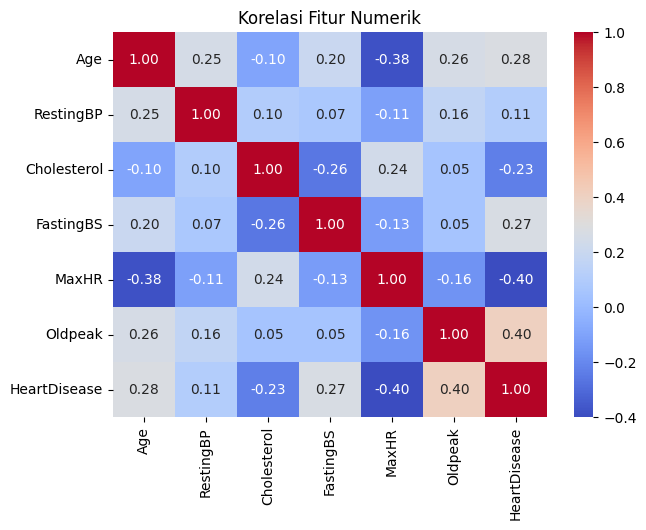

In [6]:
# Distribusi fitur numerik
num_cols_eda = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
df[num_cols_eda].hist(bins=20, figsize=(12, 7))
plt.tight_layout()
plt.show()

# Fitur kategorikal terhadap target
cat_cols_eda = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    sns.countplot(x=col, hue="HeartDisease", data=df, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# Korelasi fitur numerik
plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi Fitur Numerik")
plt.show()

In [7]:
df_clean = df.copy()
df_clean["Cholesterol"] = df_clean["Cholesterol"].replace(0, np.nan)
df_clean["RestingBP"] = df_clean["RestingBP"].replace(0, np.nan)
print(df_clean[["Cholesterol", "RestingBP"]].isnull().sum())

X = df_clean.drop(columns="HeartDisease")
y = df_clean["HeartDisease"]

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print("Fitur kategorikal:", cat_cols)
print("Fitur numerik    :", num_cols)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

Cholesterol    172
RestingBP        1
dtype: int64
Fitur kategorikal: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Fitur numerik    : ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi kelas latih:", y_train.value_counts(normalize=True).round(3).to_dict())

Data latih: (734, 11) | Data uji: (184, 11)
Proporsi kelas latih: {1: 0.553, 0: 0.447}


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM (linear)": SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}

pipelines = {name: Pipeline([("prep", preprocessor), ("clf", clf)]) for name, clf in models.items()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    print(f"{name:20s} F1 cross-val: {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression  F1 cross-val: 0.863 (+/- 0.023)
KNN                  F1 cross-val: 0.866 (+/- 0.026)
Decision Tree        F1 cross-val: 0.835 (+/- 0.029)
Random Forest        F1 cross-val: 0.870 (+/- 0.026)
SVM (linear)         F1 cross-val: 0.865 (+/- 0.029)
SVM (RBF)            F1 cross-val: 0.877 (+/- 0.031)


In [10]:
svm_pipe = Pipeline([("prep", preprocessor), ("clf", SVC(probability=True, random_state=RANDOM_STATE))])
param_grid = {
    "clf__kernel": ["linear", "rbf"],
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.1],
}
grid = GridSearchCV(svm_pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Parameter terbaik:", grid.best_params_)
print("F1 cross-val terbaik:", round(grid.best_score_, 3))

pipelines["SVM (tuned)"] = grid.best_estimator_

Parameter terbaik: {'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}
F1 cross-val terbaik: 0.878


In [11]:
results = []
for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.886,0.886,0.912,0.899,0.933
Random Forest,0.880,0.877,0.912,0.894,0.930
SVM (RBF),0.875,0.862,0.922,0.891,0.942
SVM (tuned),0.875,0.862,0.922,0.891,0.942
KNN,0.864,0.881,0.873,0.877,0.927
SVM (linear),0.853,0.895,0.833,0.863,0.933
Decision Tree,0.788,0.812,0.804,0.808,0.846


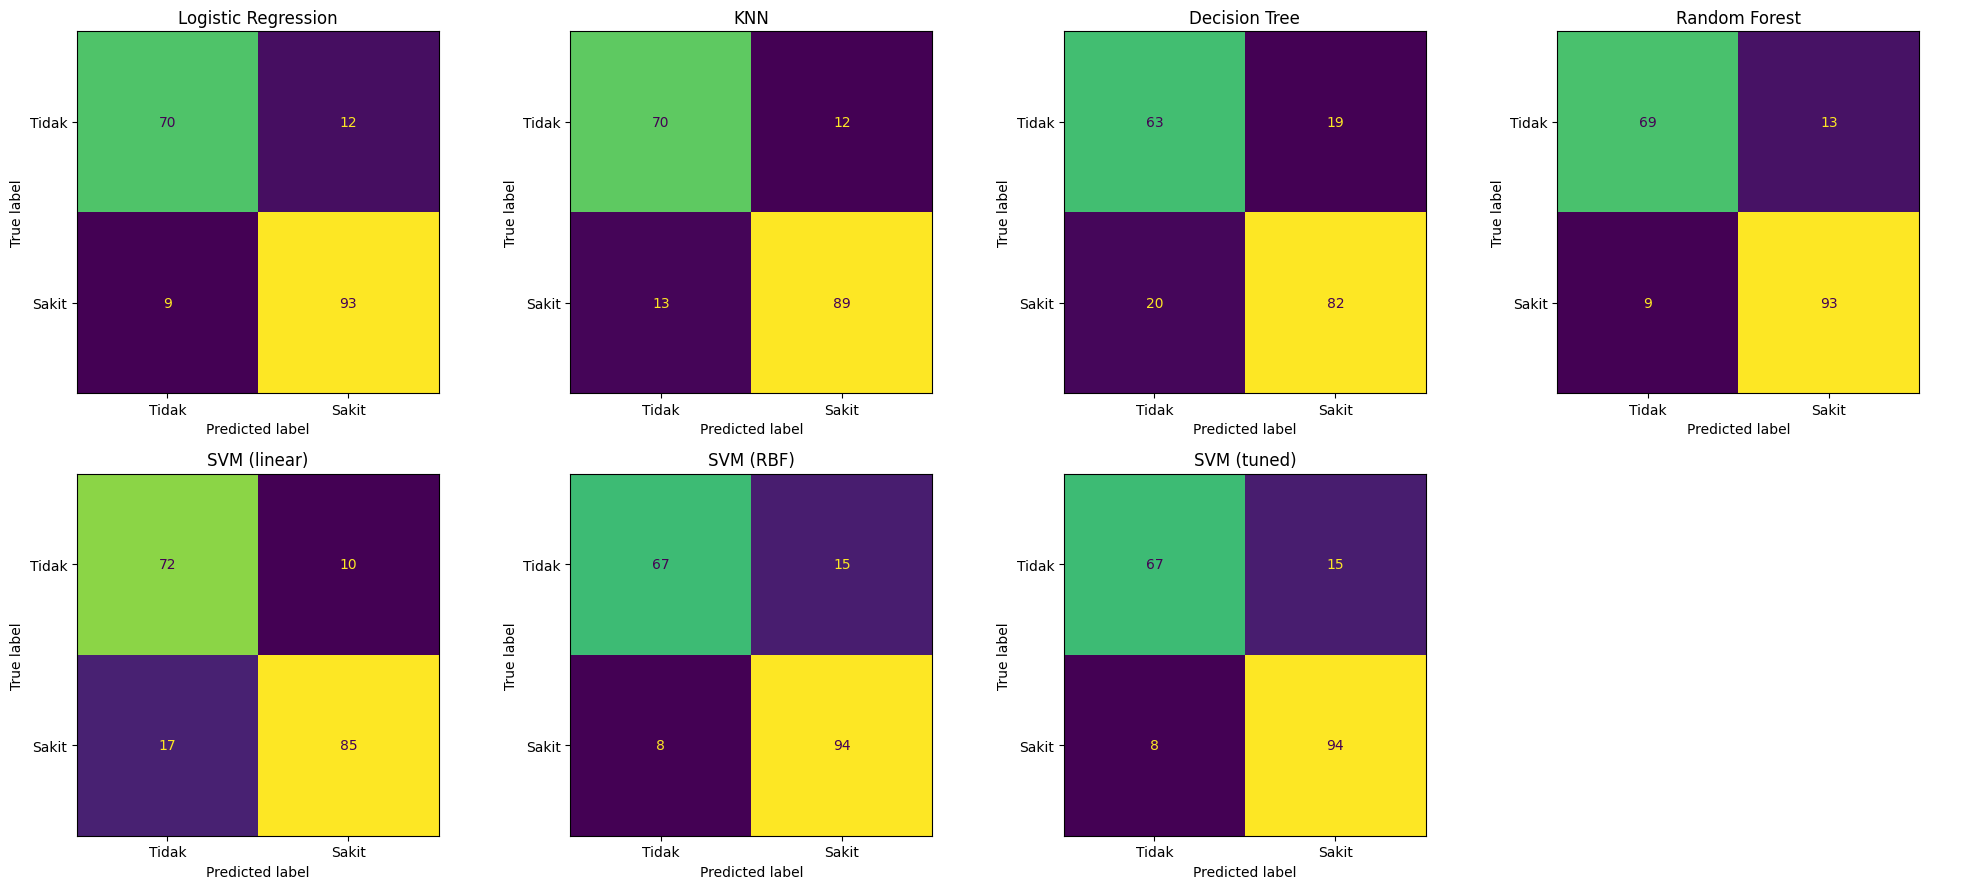

In [12]:
# Confusion matrix tiap model
n = len(pipelines)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5 * ((n + 1) // 2), 9))
for ax, (name, pipe) in zip(axes.ravel(), pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Tidak", "Sakit"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

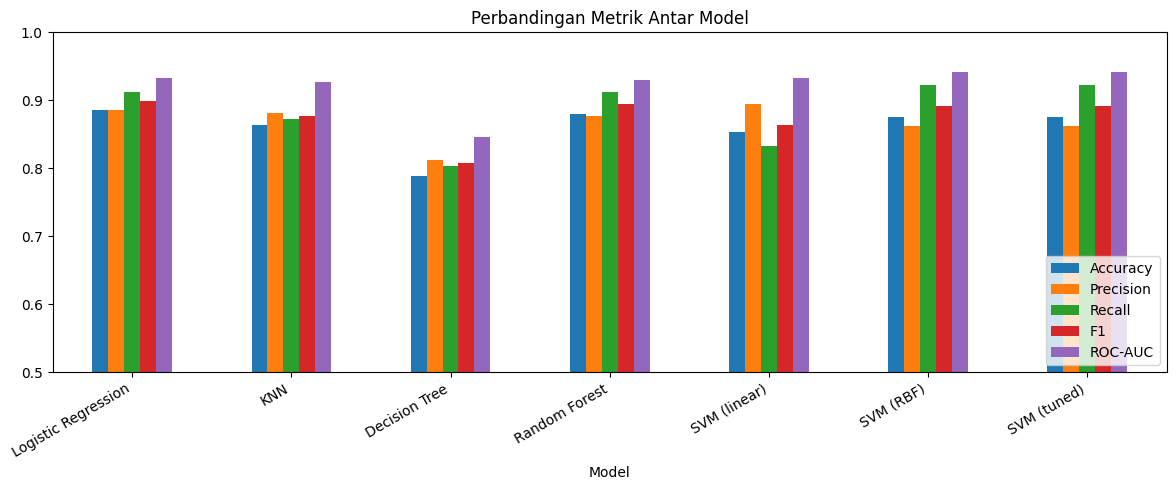

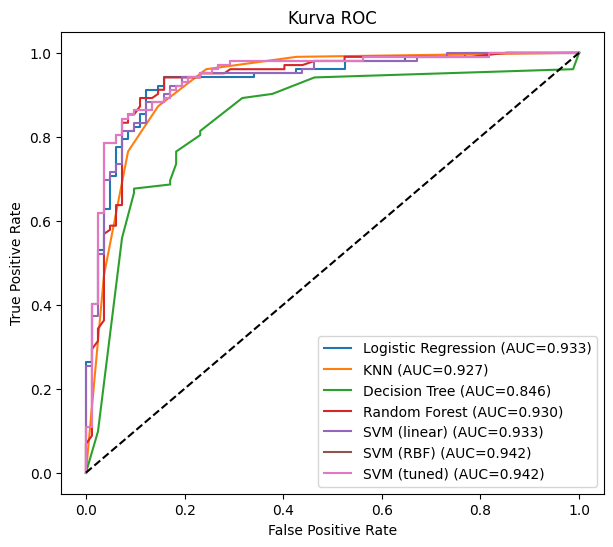

In [13]:
results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0.5, 1.0))
plt.title("Perbandingan Metrik Antar Model")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for name, pipe in pipelines.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results_df.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC")
plt.legend()
plt.show()

In [14]:
best_name = results_df["F1"].idxmax()
print("Model terbaik berdasarkan F1:", best_name)
print(results_df.loc[best_name])
best_model = pipelines[best_name]

Model terbaik berdasarkan F1: Logistic Regression
Accuracy     0.886
Precision    0.886
Recall       0.912
F1           0.899
ROC-AUC      0.933
Name: Logistic Regression, dtype: float64


In [15]:
pasien_baru = pd.DataFrame([{
    "Age": 55, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140,
    "Cholesterol": 250, "FastingBS": 1, "RestingECG": "Normal",
    "MaxHR": 120, "ExerciseAngina": "Y", "Oldpeak": 1.5, "ST_Slope": "Flat",
}])

pred = best_model.predict(pasien_baru)[0]
proba = best_model.predict_proba(pasien_baru)[0, 1]
print("Prediksi:", "Berisiko penyakit jantung" if pred == 1 else "Tidak berisiko")
print(f"Probabilitas penyakit jantung: {proba:.2%}")

Prediksi: Berisiko penyakit jantung
Probabilitas penyakit jantung: 98.53%
